# 01. Exploratory Data Analysis (EDA)

**Đề tài:** Crop Recommendation System

**Người thực hiện:** Tuấn Hùng

## 1. Giới thiệu

Mục tiêu của notebook là khám phá và phân tích bộ dữ liệu
Crop Recommendation Dataset nhằm tìm hiểu mối quan hệ
giữa các chỉ số đất đai, khí hậu và loại cây trồng phù hợp.

Các nội dung thực hiện:
- Khảo sát cấu trúc dữ liệu.
- Thống kê mô tả.
- Kiểm tra dữ liệu thiếu và trùng lặp.
- Phân tích phân bố các đặc trưng.
- Trực quan hóa dữ liệu.
- Phân tích tương quan giữa các biến.

In [1]:
# 1. Import các thư viện cần thiết
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# 2. Cấu hình font tiếng Việt cho biểu đồ
plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 11

# 3. Xác định đường dẫn dataset
data_path = Path("data/raw/Crop_recommendation.csv")

if not data_path.exists():
    data_path = Path("../data/raw/Crop_recommendation.csv")

# 4. Đọc dữ liệu
df = pd.read_csv(data_path)

# 5. Hiển thị thông tin ban đầu
print("Đã đọc dữ liệu thành công!")
print("Kích thước dữ liệu:", df.shape)

print("\n5 dòng dữ liệu đầu tiên:")
display(df.head())

Đã đọc dữ liệu thành công!
Kích thước dữ liệu: (2200, 8)

5 dòng dữ liệu đầu tiên:


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [2]:
# Kiểm tra tên cột
print("Các cột dữ liệu:")
print(df.columns.tolist())

# Kiểm tra kiểu dữ liệu
print("\nThông tin dataset:")
df.info()

# Thống kê mô tả
display(df.describe())

# Số loại cây trồng
print("Số loại cây trồng:", df["label"].nunique())

Các cột dữ liệu:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Thông tin dataset:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB


,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


Số loại cây trồng: 22


## 2. Kiểm tra chất lượng dữ liệu

Trong phần này, tiến hành kiểm tra các giá trị bị thiếu,
dữ liệu trùng lặp và sự phân bố của các loại cây trồng.

Mục đích là đánh giá chất lượng dữ liệu trước khi đưa
vào giai đoạn tiền xử lý và huấn luyện mô hình.

In [3]:
# 1. Kiểm tra giá trị thiếu
print("Số giá trị thiếu của từng cột:")
print(df.isnull().sum())

# 2. Kiểm tra dữ liệu trùng lặp
print("\nSố dòng trùng lặp:")
print(df.duplicated().sum())

# 3. Kiểm tra số lượng mẫu của từng loại cây
print("\nSố lượng mẫu theo loại cây:")
print(df["label"].value_counts())

# 4. Kiểm tra dữ liệu có cân bằng không
print("\nPhân bố tỷ lệ các loại cây (%):")
print(df["label"].value_counts(normalize=True) * 100)

Số giá trị thiếu của từng cột:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Số dòng trùng lặp:
0

Số lượng mẫu theo loại cây:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

Phân bố tỷ lệ các loại cây (%):
label
rice           4.545455
maize          4.545455
chickpea       4.545455
kidneybeans    4.545455
pigeonpeas     4.545455
mothbeans      4.545455
mungbean       4.545455
blackgram      4.545455
lentil         4.545455
pomegranate    4.545455
banana         4.545455
mango          4

### Nhận xét chất lượng dữ liệu

Bộ dữ liệu Crop Recommendation có tổng cộng 2.200 mẫu,
bao gồm 22 loại cây trồng khác nhau.

Kết quả kiểm tra cho thấy:
- Không có giá trị bị thiếu ở bất kỳ thuộc tính nào.
- Không phát hiện dòng dữ liệu trùng lặp.
- Mỗi loại cây trồng có 100 mẫu, chiếm khoảng 4,55% tổng dữ liệu.
- Dữ liệu có sự cân bằng hoàn toàn giữa các lớp nhãn.

Nhìn chung, bộ dữ liệu có chất lượng ban đầu tốt và
không cần thực hiện các thao tác loại bỏ dữ liệu thiếu
hoặc trùng lặp.

Tuy nhiên, cần tiếp tục phân tích phân bố dữ liệu,
các giá trị ngoại lệ và tương quan giữa các đặc trưng.

## 4. Phân tích phân bố các đặc trưng

Sử dụng biểu đồ Histogram để khảo sát sự phân bố của
7 thuộc tính đầu vào: N, P, K, temperature, humidity,
ph và rainfall.

In [4]:
# Danh sách các đặc trưng đầu vào
features = [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall"
]

# Tên tiếng Việt có dấu cho từng đặc trưng
feature_names = {
    "N": "Hàm lượng Nitơ (N)",
    "P": "Hàm lượng Phốt pho (P)",
    "K": "Hàm lượng Kali (K)",
    "temperature": "Nhiệt độ (°C)",
    "humidity": "Độ ẩm (%)",
    "ph": "Độ pH",
    "rainfall": "Lượng mưa (mm)"
}

# Cấu hình font tiếng Việt cho biểu đồ
plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 11

print("Đã khai báo thành công các đặc trưng!")

for col in features:
    print(f"{col} → {feature_names[col]}")

Đã khai báo thành công các đặc trưng!
N → Hàm lượng Nitơ (N)
P → Hàm lượng Phốt pho (P)
K → Hàm lượng Kali (K)
temperature → Nhiệt độ (°C)
humidity → Độ ẩm (%)
ph → Độ pH
rainfall → Lượng mưa (mm)


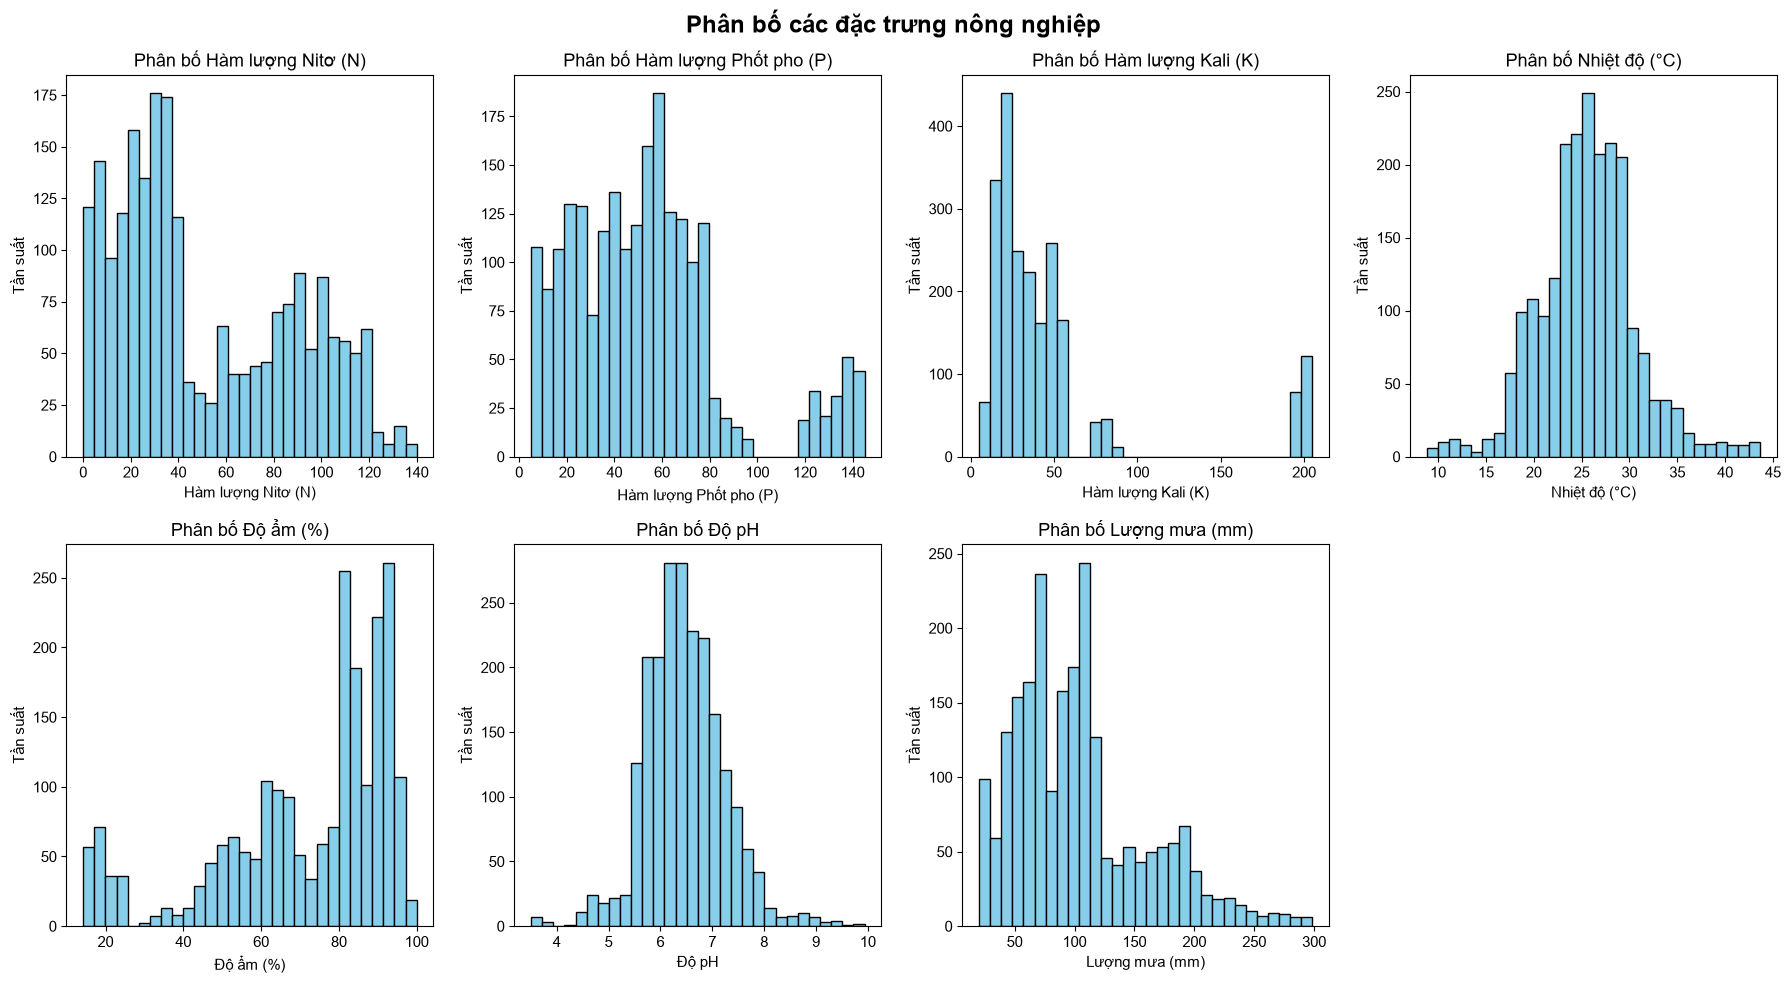

In [5]:
# Biểu đồ Histogram - Phân bố 7 đặc trưng nông nghiệp
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    axes[i].hist(
        df[col],
        bins=30,
        color="skyblue",
        edgecolor="black"
    )

    axes[i].set_title(
        f"Phân bố {feature_names[col]}"
    )
    axes[i].set_xlabel(feature_names[col])
    axes[i].set_ylabel("Tần suất")

# Xóa ô biểu đồ không sử dụng
fig.delaxes(axes[-1])

plt.suptitle(
    "Phân bố các đặc trưng nông nghiệp",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## 5. Phát hiện giá trị ngoại lệ bằng Boxplot

Biểu đồ Boxplot được sử dụng để phát hiện các giá trị
nằm ngoài khoảng phân bố thông thường của từng đặc trưng.

Việc phát hiện ngoại lệ giúp đánh giá xem dữ liệu có
cần xử lý trước khi đưa vào mô hình hay không.

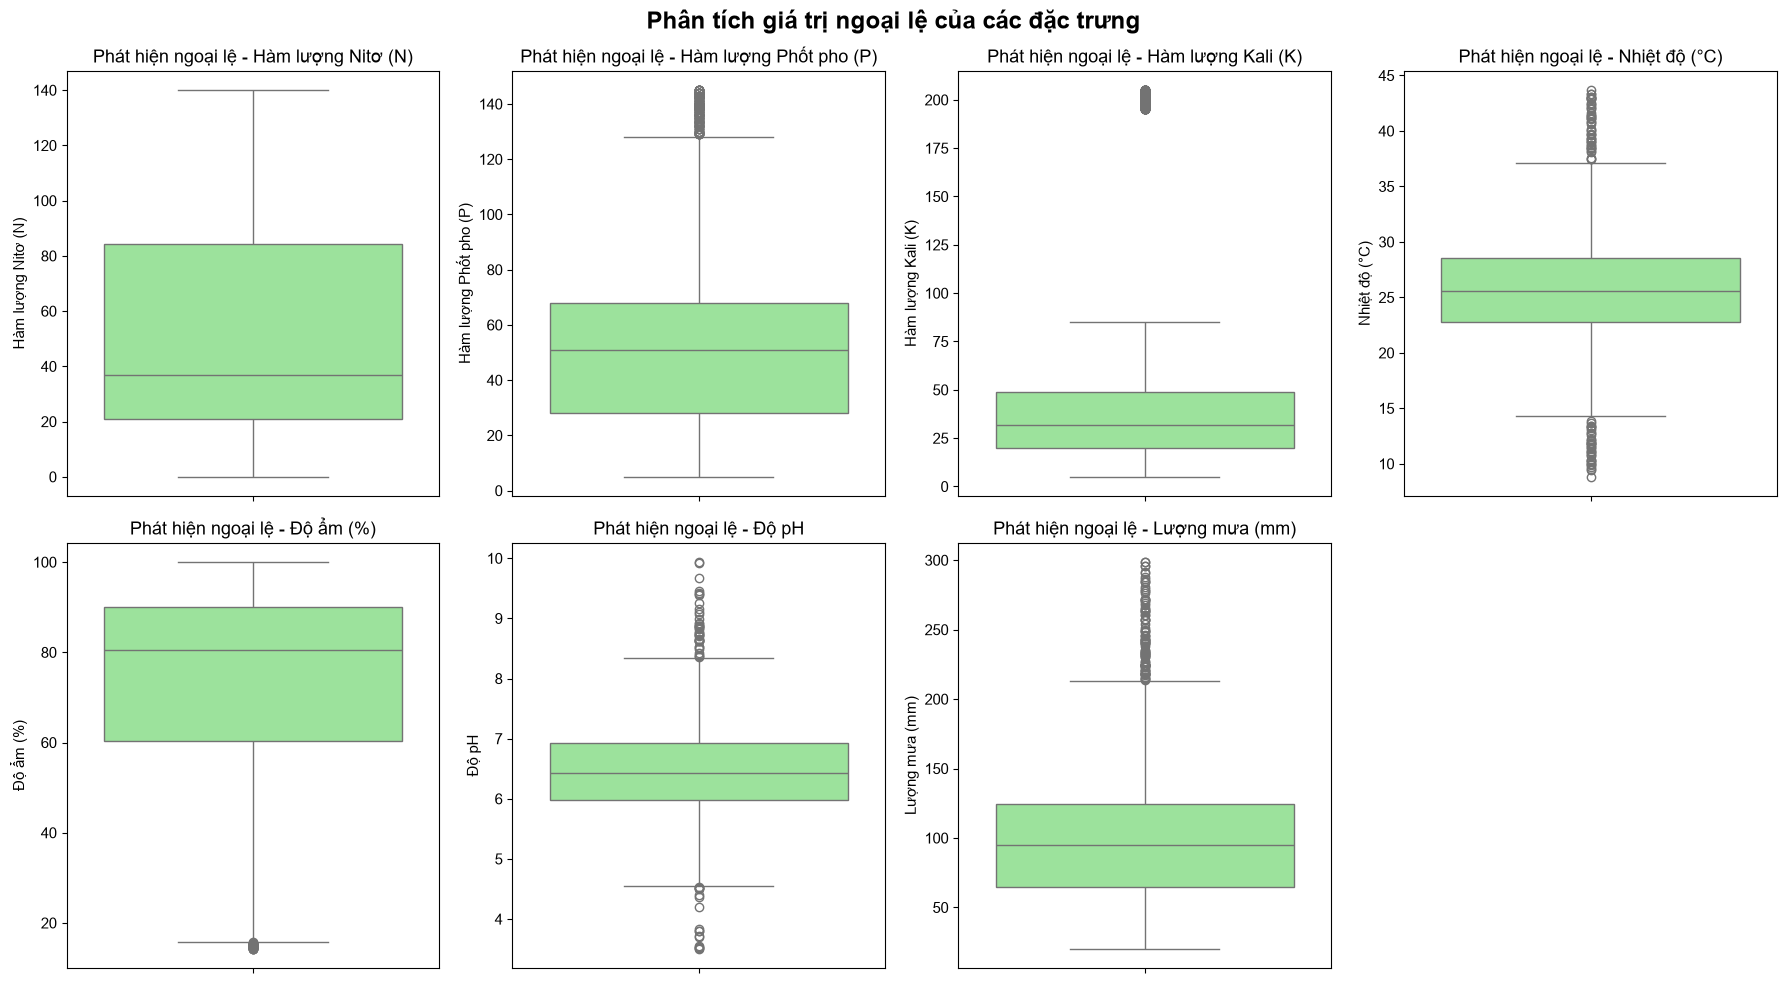

In [6]:
# Tạo 7 biểu đồ Boxplot cho các đặc trưng
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(
        y=df[col],
        ax=axes[i],
        color="lightgreen"
    )

    axes[i].set_title(
        f"Phát hiện ngoại lệ - {feature_names[col]}"
    )
    axes[i].set_ylabel(feature_names[col])

# Xóa ô biểu đồ thứ 8 không sử dụng
fig.delaxes(axes[-1])

# Đặt tiêu đề chung
plt.suptitle(
    "Phân tích giá trị ngoại lệ của các đặc trưng",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## 6. Phân tích tương quan giữa các đặc trưng

Sử dụng ma trận tương quan Pearson và biểu đồ Heatmap
để xác định mối quan hệ tuyến tính giữa các thuộc tính.

Kết quả giúp nhận diện những đặc trưng có mức tương
quan cao, phục vụ việc phân tích dữ liệu và lựa chọn
phương pháp xây dựng mô hình.

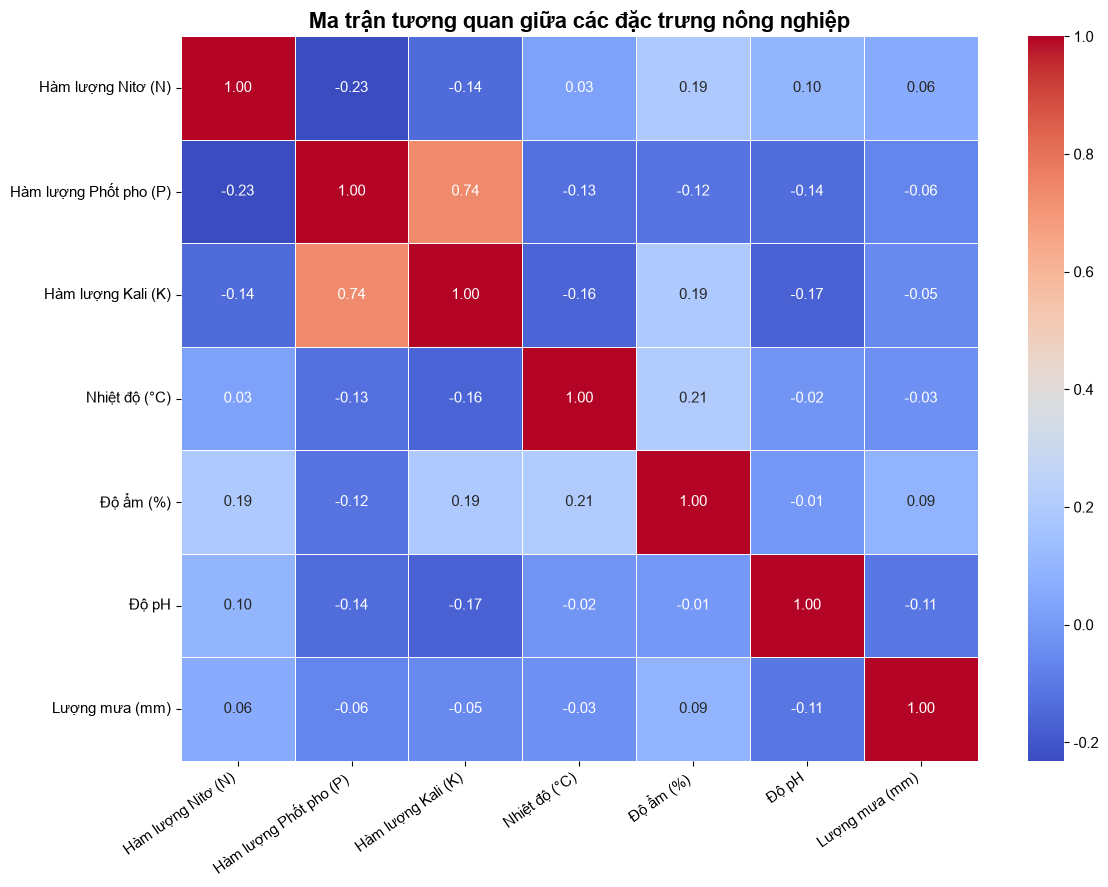

In [7]:
# Tính ma trận tương quan
correlation_matrix = df[features].corr()

# Đổi tên sang tiếng Việt
correlation_matrix = correlation_matrix.rename(
    index=feature_names,
    columns=feature_names
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Ma trận tương quan giữa các đặc trưng nông nghiệp",
    fontsize=16,
    fontweight="bold"
)

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

## 7. Tổng kết và kết luận phân tích dữ liệu

### 7.1. Tổng quan bộ dữ liệu

Bộ dữ liệu Crop Recommendation được sử dụng để xây dựng hệ thống khuyến nghị cây trồng dựa trên các yếu tố dinh dưỡng đất và điều kiện khí hậu.

Kết quả khảo sát cho thấy:

- Bộ dữ liệu có tổng cộng **2.200 mẫu dữ liệu**.
- Có **7 đặc trưng đầu vào**, bao gồm N, P, K, nhiệt độ, độ ẩm, độ pH và lượng mưa.
- Thuộc tính mục tiêu là `label`, đại diện cho loại cây trồng được khuyến nghị.
- Có **22 loại cây trồng**, mỗi loại gồm 100 mẫu.

### 7.2. Đánh giá chất lượng dữ liệu

Quá trình kiểm tra chất lượng dữ liệu ghi nhận:

- Không phát hiện giá trị bị thiếu ở bất kỳ thuộc tính nào.
- Không phát hiện dòng dữ liệu trùng lặp.
- Các đặc trưng đầu vào đều có kiểu dữ liệu số.
- Các lớp nhãn phân bố cân bằng, mỗi loại cây chiếm khoảng 4,55% tổng số mẫu.

Nhìn chung, dữ liệu có chất lượng ban đầu tốt và thuận lợi cho quá trình xây dựng mô hình học máy.

### 7.3. Kết quả phân tích trực quan

**Biểu đồ phân bố cây trồng:** Cho thấy số lượng mẫu giữa các loại cây được phân bố đồng đều.

**Biểu đồ Histogram:** Giúp quan sát sự phân bố và khoảng biến thiên của từng đặc trưng nông nghiệp.

**Biểu đồ Boxplot:** Hỗ trợ phát hiện các giá trị nằm ngoài khoảng phân bố thông thường. Những giá trị này cần được đánh giá trước khi quyết định xử lý.

**Biểu đồ Heatmap:** Thể hiện mức độ tương quan tuyến tính giữa các đặc trưng, hỗ trợ phân tích mối quan hệ giữa các yếu tố dinh dưỡng và khí hậu.

### 7.4. Kết luận

Qua quá trình phân tích khám phá dữ liệu, có thể kết luận rằng bộ dữ liệu Crop Recommendation đáp ứng các điều kiện cơ bản để tiếp tục giai đoạn tiền xử lý và xây dựng mô hình phân loại cây trồng.

Ở giai đoạn tiếp theo, dữ liệu sẽ được kiểm tra tính hợp lệ, chuẩn bị các đặc trưng đầu vào, chia tập huấn luyện và kiểm tra, đồng thời áp dụng những phương pháp tiền xử lý phù hợp với các thuật toán học máy.

Kết quả này sẽ được bàn giao cho thành viên phụ trách huấn luyện và đánh giá mô hình.